
# Portfolio Risk Analysis

This notebook evaluates the risk characteristics and benchmark-relative performance of the portfolio.

We focus on:

- Portfolio volatility and covariance
- Correlation and diversification
- Value at Risk (VaR)
- Conditional VaR (CVaR / Expected Shortfall)
- VaR backtesting
- Risk contribution
- Historical stress testing
- Maximum drawdown
- Benchmark comparison
- Portfolio beta

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
adj_close = pd.read_csv(
    "../data/adj_close.csv",
    index_col=0,
    parse_dates=True
)

returns = adj_close.pct_change().dropna()

returns.head()

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
Date,,,,,,,,,
2019-01-03,-0.099608,-0.055151,-0.005885,-0.038097,-0.036788,-0.060417,0.008121,-0.002191,-0.026815
2019-01-04,0.042689,0.043270,0.048514,0.030782,0.046509,0.064068,0.003604,0.022631,0.039183
2019-01-07,-0.002226,0.022847,-0.001473,-0.001792,0.001275,0.052941,0.006337,0.001321,-0.013106
2019-01-08,0.019063,-0.007361,0.005039,0.031312,0.007251,-0.024895,0.014693,-0.006102,0.003984
2019-01-09,0.016982,0.041488,-0.002690,0.011603,0.014300,0.019667,0.010964,0.011616,0.003663


In [3]:
weights = np.repeat(1 / len(returns.columns), len(returns.columns))

portfolio_returns = pd.Series(
    np.dot(returns, weights),
    index=returns.index
)

portfolio_returns.head()

Date
2019-01-03   -0.035203
2019-01-04    0.037917
2019-01-07    0.007347
2019-01-08    0.004776
2019-01-09    0.014177
dtype: float64

# 1. Diversification Analysis

# 1.1- Correlation matrix

In [4]:

correlation_matrix = returns.corr()
correlation_matrix

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
AAPL,1.000000,0.565380,0.212148,0.313760,0.701021,0.578922,0.255570,0.292929,0.294424
ASML,0.565380,1.000000,0.263537,0.412849,0.607866,0.687766,0.305087,0.359884,0.433128
BNP.PA,0.212148,0.263537,1.000000,0.481742,0.199680,0.178725,0.071652,0.467951,0.589294
MC.PA,0.313760,0.412849,0.481742,1.000000,0.314592,0.267387,0.190016,0.309050,0.579725
MSFT,0.701021,0.607866,0.199680,0.314592,1.000000,0.666673,0.290545,0.283157,0.301403
NVDA,0.578922,0.687766,0.178725,0.267387,0.666673,1.000000,0.257726,0.256725,0.306092
NVO,0.255570,0.305087,0.071652,0.190016,0.290545,0.257726,1.000000,0.143390,0.157231
SHEL,0.292929,0.359884,0.467951,0.309050,0.283157,0.256725,0.143390,1.000000,0.386639
SIE.DE,0.294424,0.433128,0.589294,0.579725,0.301403,0.306092,0.157231,0.386639,1.000000


# 1.2 - Covariance Matrix

In [5]:
cov_matrix = returns.cov()
cov_matrix

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
AAPL,0.000373,0.000278,0.000085,0.000112,0.000239,0.000358,0.000101,0.000116,0.000107
ASML,0.000278,0.000650,0.000139,0.000195,0.000273,0.000562,0.000160,0.000189,0.000207
BNP.PA,0.000085,0.000139,0.000430,0.000185,0.000073,0.000119,0.000031,0.000200,0.000229
MC.PA,0.000112,0.000195,0.000185,0.000343,0.000103,0.000159,0.000072,0.000118,0.000202
MSFT,0.000239,0.000273,0.000073,0.000103,0.000311,0.000376,0.000105,0.000103,0.000100
NVDA,0.000358,0.000562,0.000119,0.000159,0.000376,0.001027,0.000170,0.000169,0.000184
NVO,0.000101,0.000160,0.000031,0.000072,0.000105,0.000170,0.000423,0.000061,0.000061
SHEL,0.000116,0.000189,0.000200,0.000118,0.000103,0.000169,0.000061,0.000423,0.000149
SIE.DE,0.000107,0.000207,0.000229,0.000202,0.000100,0.000184,0.000061,0.000149,0.000352


# 2. Portfolio Risk

# 2.1 - Portfolio Volatility

In [6]:


portfolio_volatility = np.sqrt(
    np.dot(weights, np.dot(cov_matrix, weights))
)

print(f"Portfolio Volatility: {portfolio_volatility:.2%}")

Portfolio Volatility: 1.43%


In [7]:
annual_portfolio_volatility = portfolio_volatility * np.sqrt(252)

print(f"Annualized Portfolio Volatility: {annual_portfolio_volatility:.2%}")

Annualized Portfolio Volatility: 22.66%


# 2.2 VAR

In [8]:

var_95 = portfolio_returns.quantile(0.05)

print(f"95% Daily VaR: {var_95:.2%}")

95% Daily VaR: -2.08%


**Method:** Historical VaR based on the portfolio's observed historical returns.

**Limitation:** Historical VaR assumes that past return patterns are useful for estimating future losses. This assumption may fail during extreme market events.


#Value at Risk (VaR)

VaR estimates the potential loss of a portfolio over a given time period at a chosen confidence level.

Our 95% Daily VaR is **-2.08%**.

This means that historically, about 95% of trading days had returns better than -2.08%, while the worst 5% of days experienced losses greater than 2.08%.

VaR focuses on the left tail of the return distribution and helps quantify downside risk.

# 2.3- Conditional VaR / Expected Shortfall

In [9]:
worst_5_percent = portfolio_returns[portfolio_returns <= var_95] #a dataset containing the worst 5% of historical daily returns.
worst_5_percent 

Date
2019-01-03   -0.035203
2019-01-28   -0.023848
2019-03-22   -0.025118
2019-05-07   -0.023481
2019-05-13   -0.030943
                ...   
2025-04-04   -0.056788
2025-04-16   -0.023141
2025-07-29   -0.027549
2025-10-10   -0.027779
2025-11-13   -0.022600
Length: 91, dtype: float64

In [10]:
cvar_95 = worst_5_percent.mean()

print(f"95% CVaR: {cvar_95:.2%}")

95% CVaR: -3.31%


#CVaR / Expected Shortfall

CVaR measures the average loss in the worst 5% of historical trading days.

Our 95% CVaR is **-3.31%**.

This means that when the portfolio entered its worst 5% of days, the average daily loss was approximately 3.31%.

CVaR complements VaR because it tells us how severe losses are beyond the VaR threshold.

# 2.4- Individual Stock Volatility

In [11]:
#Individual stock volatility measures the historical variability of each stock's daily returns.
#Higher volatility means the stock's returns have fluctuated more and therefore represent greater standalone risk.
stock_volatility = returns.std()
stock_volatility

AAPL      0.019310
ASML      0.025493
BNP.PA    0.020726
MC.PA     0.018528
MSFT      0.017625
NVDA      0.032040
NVO       0.020566
SHEL      0.020576
SIE.DE    0.018769
dtype: float64

# 2.5- Risk contribution

Risk contribution identifies how much each holding contributes to total portfolio risk.

The simplified measure uses:

Risk Contribution ≈ Weight × Stock Volatility

A more rigorous decomposition accounts for the covariance between assets.

Marginal Contribution to Risk (MCR) measures each asset's incremental contribution to portfolio variance.

Component Contribution to Risk (CCtR) converts this into each asset's share of total portfolio volatility.

The final risk contribution percentages sum to approximately 100%.

In [12]:
risk_contribution = weights * stock_volatility

risk_contribution

AAPL      0.002146
ASML      0.002833
BNP.PA    0.002303
MC.PA     0.002059
MSFT      0.001958
NVDA      0.003560
NVO       0.002285
SHEL      0.002286
SIE.DE    0.002085
dtype: float64

In [13]:
risk_contribution_pct = risk_contribution * 100
risk_contribution_pct

AAPL      0.214558
ASML      0.283251
BNP.PA    0.230294
MC.PA     0.205869
MSFT      0.195837
NVDA      0.355996
NVO       0.228510
SHEL      0.228627
SIE.DE    0.208550
dtype: float64

In [14]:
## marginal contribution
import numpy as np
marginal_contribution = np.dot(cov_matrix, weights) / portfolio_volatility
marginal_contribution

array([0.01377321, 0.0206495 , 0.01159403, 0.01158721, 0.01309228,
       0.02430905, 0.00921354, 0.01189102, 0.01238142])

In [15]:
## Component Contribution to Risk

cctr = weights * marginal_contribution 

cctr

array([0.00153036, 0.00229439, 0.00128823, 0.00128747, 0.0014547 ,
       0.00270101, 0.00102373, 0.00132122, 0.00137571])

In [16]:
cctr_pct = cctr / portfolio_volatility * 100

cctr_pct

array([10.71918127, 16.07073927,  9.0232054 ,  9.01789969, 10.18923961,
       18.91883436,  7.170555  ,  9.25434132,  9.63600408])

In [17]:
#array to stock names and put the biggest risk contributors at the top.
#who contributes the most risk
risk_share = pd.Series(cctr_pct, index=returns.columns)

risk_share.sort_values(ascending=False)

NVDA      18.918834
ASML      16.070739
AAPL      10.719181
MSFT      10.189240
SIE.DE     9.636004
SHEL       9.254341
BNP.PA     9.023205
MC.PA      9.017900
NVO        7.170555
dtype: float64

# 3. Historical Stress Testing

This section evaluates how the portfolio behaved during a historical market stress event.

We use the COVID-19 market shock as a stress scenario and examine:

- Portfolio return during the stress period
- Maximum drawdown during the stress period
- Changes in correlation during market stress

## 3.1 - Select COVID period

In [18]:
covid_returns = returns.loc["2020-02-01":"2020-04-30"]

covid_returns.head()

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
Date,,,,,,,,,
2020-02-03,-0.002747,0.026723,0.006140,0.003668,0.024379,0.016495,0.002137,-0.017449,-0.003762
2020-02-04,0.033014,0.038416,0.019652,0.034909,0.032916,0.028294,0.010335,0.008001,0.015824
2020-02-05,0.008154,0.023694,0.006492,0.010716,-0.001221,0.014689,0.045787,0.025170,0.006550
2020-02-06,0.011697,0.010544,0.016126,0.007349,0.020734,0.013918,0.004037,-0.015298,-0.006524
2020-02-07,-0.013593,-0.014795,0.028169,-0.009807,0.001416,-0.010462,-0.021958,-0.006713,-0.003497


## 3.2 - Calculate portfolio returns

In [19]:
covid_portfolio_returns = np.dot(covid_returns, weights)

covid_portfolio_returns[:5] 


array([ 0.00617599,  0.02459579,  0.01555895,  0.00695369, -0.0056933 ])

## 3.3 - Calculate cumulative growth

In [20]:
covid_cumulative = (1 + covid_portfolio_returns).cumprod()
covid_cumulative

array([1.00617599, 1.03092369, 1.04696378, 1.05424404, 1.04824191,
       1.05818772, 1.06316202, 1.07628627, 1.06759517, 1.07466804,
       1.07698776, 1.07277712, 1.08862571, 1.07460735, 1.0565371 ,
       1.00750344, 0.98164024, 0.98780544, 0.94323375, 0.94337579,
       0.97289665, 0.95670411, 0.98914976, 0.95691137, 0.93169757,
       0.84981878, 0.884367  , 0.85510592, 0.76239789, 0.81305555,
       0.71893355, 0.75654491, 0.69067653, 0.71341063, 0.71647329,
       0.72538787, 0.80401631, 0.82698585, 0.85821424, 0.81906096,
       0.84910961, 0.84578515, 0.81245742, 0.83218582, 0.81437308,
       0.8659957 , 0.86586198, 0.87565769, 0.88025096, 0.8807146 ,
       0.9025343 , 0.8750065 , 0.88069339, 0.90139215, 0.89225463,
       0.86282794, 0.89197433, 0.89399478, 0.89564449, 0.91306627,
       0.91907251, 0.9452364 , 0.9151717 ])

## 3.4 - Calculate total COVID-period return

In [21]:
covid_total_return = covid_cumulative[-1] - 1

print(f"COVID Period Return: {covid_total_return:.2%}")

COVID Period Return: -8.48%


## 3.5 - Calculate running peak

In [22]:
covid_peak = np.maximum.accumulate(covid_cumulative)
covid_peak

array([1.00617599, 1.03092369, 1.04696378, 1.05424404, 1.05424404,
       1.05818772, 1.06316202, 1.07628627, 1.07628627, 1.07628627,
       1.07698776, 1.07698776, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571, 1.08862571, 1.08862571,
       1.08862571, 1.08862571, 1.08862571])

## 3.6 - Covid drawdown

In [23]:
covid_drawdown = (covid_cumulative - covid_peak) / covid_peak
covid_drawdown 

array([ 0.        ,  0.        ,  0.        ,  0.        , -0.0056933 ,
        0.        ,  0.        ,  0.        , -0.00807508, -0.00150354,
        0.        , -0.00390965,  0.        , -0.01287712, -0.02947626,
       -0.07451805, -0.09827571, -0.09261243, -0.13355551, -0.13342503,
       -0.10630749, -0.12118178, -0.09137755, -0.12099139, -0.14415252,
       -0.21936551, -0.18762988, -0.2145088 , -0.29966941, -0.25313582,
       -0.33959528, -0.30504589, -0.36555189, -0.34466858, -0.34185526,
       -0.33366641, -0.26143917, -0.24033959, -0.21165353, -0.24761931,
       -0.22001694, -0.22307075, -0.25368525, -0.23556296, -0.25192555,
       -0.20450556, -0.20462839, -0.19563015, -0.19141083, -0.19098493,
       -0.17094159, -0.19622833, -0.19100442, -0.17199076, -0.18038439,
       -0.20741543, -0.18064187, -0.1787859 , -0.1772705 , -0.16126703,
       -0.15574977, -0.1317159 , -0.15933301])

In [24]:
covid_max_drawdown = covid_drawdown.min()

print(f"COVID Maximum Drawdown: {covid_max_drawdown:.2%}")

COVID Maximum Drawdown: -36.56%


example:
Peak → €1.00
        ↓
Trough → €0.70

Drawdown = -30%

In [25]:
trough = np.argmin(covid_drawdown)

print(f"Worst Drawdown Date: {covid_returns.index[trough].date()}")

Worst Drawdown Date: 2020-03-18


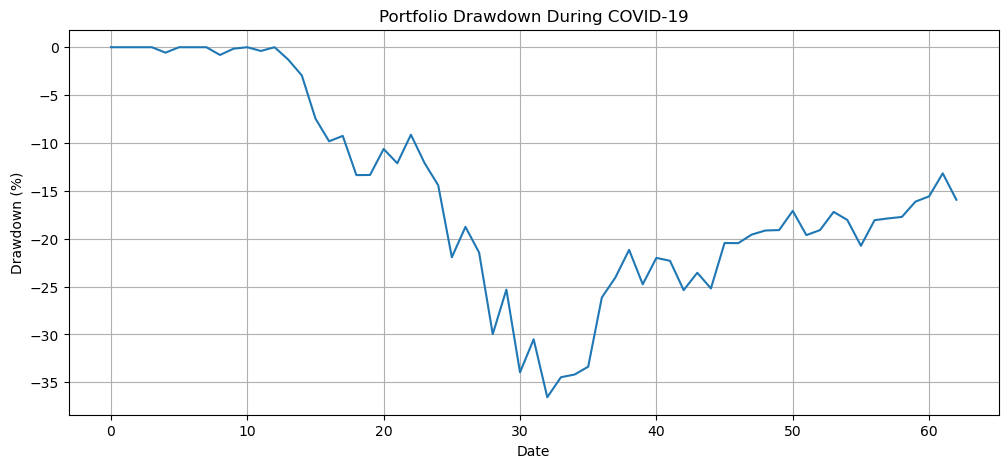

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(covid_drawdown * 100)

plt.title("Portfolio Drawdown During COVID-19")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.grid(True)

plt.show()

## 3.7 - Correlation under stress vs. normal conditions.

To assess whether diversification changed during the COVID-19 stress period, we compare the correlation matrix during normal market conditions (2019) with the correlation matrix during the COVID-19 stress period.

A positive value indicates that the correlation between two assets increased during the stress period, while a negative value indicates that it decreased.

In [27]:
# Calculate daily returns
returns = adj_close.pct_change().dropna()

# Correlation during normal conditions
normal_returns = returns.loc["2019-01-01":"2019-12-31"]
normal_corr = normal_returns.corr()

# Correlation during COVID stress
covid_corr = covid_returns.corr()

# Change in correlation
corr_diff = covid_corr - normal_corr

corr_diff

,AAPL,ASML,BNP.PA,MC.PA,MSFT,NVDA,NVO,SHEL,SIE.DE
AAPL,0.000000,0.144239,0.217300,0.119735,0.319905,0.277016,0.514911,0.197703,0.025105
ASML,0.144239,0.000000,0.201337,0.282296,0.180476,0.189738,0.425128,0.406289,0.211387
BNP.PA,0.217300,0.201337,0.000000,0.344141,0.213486,0.238646,0.404622,0.437885,0.162902
MC.PA,0.119735,0.282296,0.344141,0.000000,0.138041,0.278843,0.285668,0.425790,0.295911
MSFT,0.319905,0.180476,0.213486,0.138041,0.000000,0.331297,0.494147,0.271564,0.061594
NVDA,0.277016,0.189738,0.238646,0.278843,0.331297,0.000000,0.513295,0.263276,0.141224
NVO,0.514911,0.425128,0.404622,0.285668,0.494147,0.513295,0.000000,0.326911,0.139119
SHEL,0.197703,0.406289,0.437885,0.425790,0.271564,0.263276,0.326911,0.000000,0.287021
SIE.DE,0.025105,0.211387,0.162902,0.295911,0.061594,0.141224,0.139119,0.287021,0.000000


### Interpretation

The correlation difference matrix shows how the relationships between assets changed during the COVID-19 stress period compared with normal market conditions in 2019.

Most of the pairwise correlations increased during the COVID-19 period, as shown by the positive values in the matrix. This indicates that the assets tended to move more closely together during the market stress.

Higher correlations can reduce diversification benefits because assets become more likely to move in the same direction during a crisis.

Overall, the stress test suggests that diversification was less effective during the COVID-19 market shock.

## 4. Risk Analysis Summary

The portfolio shows strong historical performance, but the risk analysis highlights several important sources of risk.

- The portfolio's historical volatility is approximately 22.66% annualized.
- The 95% daily VaR is -2.08%, meaning that approximately 5% of historical trading days experienced losses worse than 2.08%.
- The 95% CVaR is -3.31%, showing that losses beyond the VaR threshold were more severe on average.
- NVIDIA contributes the largest share of portfolio risk under the simplified risk-contribution analysis.
- During the COVID-19 stress period, the portfolio experienced a maximum drawdown of -36.56%.
- Average pairwise correlation increased from 0.39 in 2019 to 0.67 during COVID-19, showing that diversification benefits weakened during market stress.

Overall, the analysis demonstrates that portfolio risk cannot be assessed using volatility alone. Tail risk, drawdowns, individual stock risk contributions, correlations, and stress-period behaviour provide a more complete view of the portfolio's risk profile.

# 5.  Benchmark Analysis — S&P 500

In [28]:
import yfinance as yf

benchmark_data = yf.download(
    "^GSPC",
    start="2019-01-01",
    end="2026-01-01",
    auto_adjust=False
)

benchmark_data.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC
Date,,,,,,
2019-01-02,2510.030029,2510.030029,2519.489990,2467.469971,2476.959961,3733160000
2019-01-03,2447.889893,2447.889893,2493.139893,2443.959961,2491.919922,3858830000
2019-01-04,2531.939941,2531.939941,2538.070068,2474.330078,2474.330078,4234140000
2019-01-07,2549.689941,2549.689941,2566.159912,2524.560059,2535.610107,4133120000
2019-01-08,2574.409912,2574.409912,2579.820068,2547.560059,2568.110107,4120060000


In [29]:
benchmark_prices = benchmark_data["Close"]["^GSPC"]

benchmark_prices.head()

Date
2019-01-02    2510.030029
2019-01-03    2447.889893
2019-01-04    2531.939941
2019-01-07    2549.689941
2019-01-08    2574.409912
Name: ^GSPC, dtype: float64

In [30]:
benchmark_returns = benchmark_prices.pct_change().dropna()

benchmark_returns.head()

Date
2019-01-03   -0.024757
2019-01-04    0.034336
2019-01-07    0.007010
2019-01-08    0.009695
2019-01-09    0.004098
Name: ^GSPC, dtype: float64

In [31]:
comparison = pd.concat(
    [portfolio_returns, benchmark_returns],
    axis=1,
    join="inner"
)

comparison.columns = ["Portfolio", "S&P 500"]

comparison.head()

,Portfolio,S&P 500
Date,,
2019-01-03,-0.035203,-0.024757
2019-01-04,0.037917,0.034336
2019-01-07,0.007347,0.007010
2019-01-08,0.004776,0.009695
2019-01-09,0.014177,0.004098


# 5.1 - BETA Calculation

In [32]:
beta = (
    comparison["Portfolio"].cov(comparison["S&P 500"])
    / comparison["S&P 500"].var()
)

print(f"Portfolio Beta: {beta:.2f}")

Portfolio Beta: 1.00


In [33]:
print("Portfolio-Benchmark Correlation:", comparison["Portfolio"].corr(comparison["S&P 500"]))
print("Portfolio Volatility:", comparison["Portfolio"].std())
print("S&P 500 Volatility:", comparison["S&P 500"].std())
print("Portfolio Beta:", beta)

Portfolio-Benchmark Correlation: 0.872031117352924
Portfolio Volatility: 0.014467491622275978
S&P 500 Volatility: 0.012561918382404667
Portfolio Beta: 1.0043133939111262


# 5.2 - S&P 500 cumulative growth

In [34]:
benchmark_growth = (1 + benchmark_returns).cumprod()

benchmark_growth.head()

Date
2019-01-03    0.975243
2019-01-04    1.008729
2019-01-07    1.015801
2019-01-08    1.025649
2019-01-09    1.029852
Name: ^GSPC, dtype: float64

# 5.3 - portfolio_growth

In [35]:
portfolio_growth = (1 + portfolio_returns).cumprod()

portfolio_growth.head()

Date
2019-01-03    0.964797
2019-01-04    1.001379
2019-01-07    1.008736
2019-01-08    1.013554
2019-01-09    1.027923
dtype: float64

# Normalize both

In [36]:
## Benchmark-Adjusted Performance
portfolio_growth_normalized = portfolio_growth / portfolio_growth.iloc[0]
benchmark_growth_normalized = benchmark_growth / benchmark_growth.iloc[0]

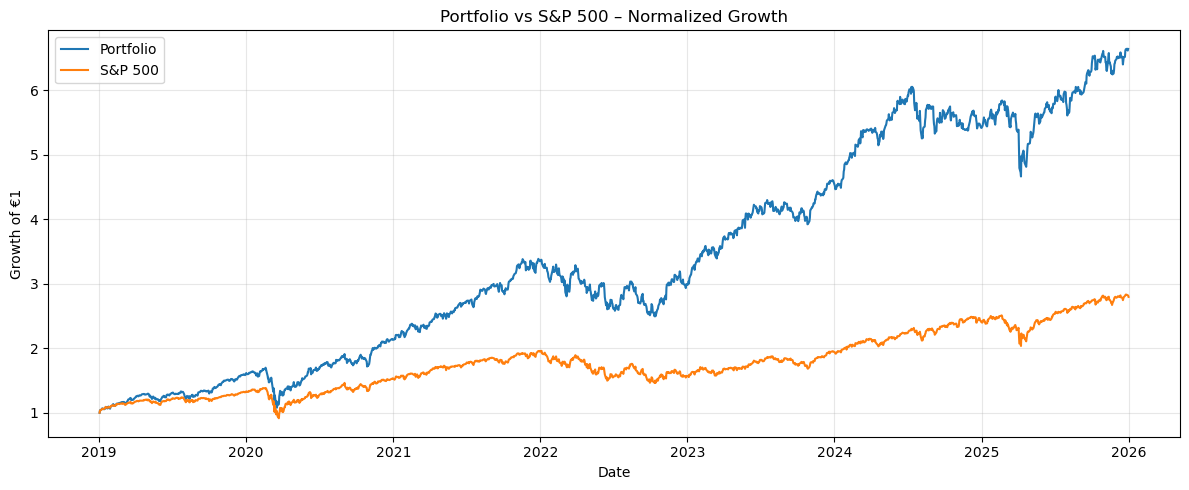

In [37]:
plt.figure(figsize=(12, 5))

plt.plot(portfolio_growth_normalized, label="Portfolio")
plt.plot(benchmark_growth_normalized, label="S&P 500")

plt.title("Portfolio vs S&P 500 – Normalized Growth")
plt.xlabel("Date")
plt.ylabel("Growth of €1")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5.4 - benchmark performance

In [38]:
portfolio_growth_normalized.iloc[-1], benchmark_growth_normalized.iloc[-1]

(np.float64(6.643081152725035), np.float64(2.7964901610792183))

In [39]:
### Difference in Final Growth vs Benchmark - The portfolio ended approximately 3.85× higher in growth value than the S&P 500 over the period.
portfolio_growth_normalized.iloc[-1] - benchmark_growth_normalized.iloc[-1]

np.float64(3.8465909916458165)

## 6. VaR Backtesting

VaR backtesting evaluates whether the historical VaR estimate provides a reasonable
representation of the portfolio's observed downside risk.

For a 95% VaR, approximately 5% of historical daily returns are expected to fall
below the VaR threshold.

We compare the observed VaR exceptions with this expected frequency.

In [40]:
# 95% VaR threshold
var_95 = portfolio_returns.quantile(0.05)

# Identify days when the actual return was worse than the VaR threshold
var_exceptions = portfolio_returns < var_95

# Count the number of exceptions
exception_count = var_exceptions.sum()

# Calculate the observed exception rate
exception_rate = var_exceptions.mean()

print(f"95% VaR: {var_95:.2%}")
print(f"VaR Exceptions: {exception_count}")
print(f"Observed Exception Rate: {exception_rate:.2%}")
print("Expected Exception Rate: 5.00%")

95% VaR: -2.08%
VaR Exceptions: 91
Observed Exception Rate: 5.03%
Expected Exception Rate: 5.00%


#### VaR Backtesting — Interpretation

The 95% historical VaR is **-2.08%**, meaning that losses worse than this
threshold are expected to occur on approximately 5% of trading days.

The backtest identified **91 VaR exceptions**, corresponding to an observed
exception rate of **5.03%**, compared with the expected rate of **5.00%**.

The close alignment between the observed and expected exception rates indicates that the historical VaR threshold is consistent with the 5% tail frequency observed in the sample.

However, this is a basic in-sample historical validation. Because the VaR threshold is estimated from the same historical observations used in the backtest, the result should not be interpreted as evidence that the model will remain accurate under future market conditions.